# Ramsey sequence with a custom Hamiltonian

This notebook follows a spin $J$ (dimension $N = 2J+1$) through the sequence

1. prepare $|\phi\rangle = |J, J\rangle$,
2. apply a $\pi/2$ pulse about $x$,
3. evolve with a Hamiltonian $H$ of your choice for a time $t$,
4. apply a second $\pi/2$ pulse about $x$,

$$|\psi(t)\rangle = e^{-i\frac{\pi}{2}S_x}\; e^{-iHt}\; e^{-i\frac{\pi}{2}S_x}\,|J, J\rangle ,$$

and plots the population of the **ground state** $|J, -J\rangle$ (all the spins down),
$P_g(t) = |\langle J,-J|\psi(t)\rangle|^2$, against $t$. It uses the C++ class `spin::Qudit` through the Python
module `spinlib`.

| Section | What it does |
|---|---|
| 1. Setup | imports `spinlib` (built by `notebook_cpy_playground.ipynb`) |
| 2. The sequence | spin matrices, the sequence and the ground-state population as functions |
| 3. Scans in $t$ | a check against the exact result, then your own Hamiltonian |
| 4. On the Bloch sphere | the state after each step of the sequence |

**Basis convention.** Index $k = 0,\dots,N-1$ is the Dicke state $|J, m\rangle$ with $m = J - k$, so
$|J,J\rangle = (1, 0, \dots, 0)$ and the ground state $|J,-J\rangle$ is the last index, $k = N-1$.

## 1. Setup

This notebook only **imports** the Python module `spinlib`: it is built from the C++ sources in `../src_cpp` by
section 1 of `notebook_cpy_playground.ipynb`. Run that section once before this notebook, and again after any
change to `qudit.hpp` or `spin_bindings.cpp` (then restart this kernel too).

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go            # preinstalled on Colab; otherwise:  %pip install plotly

# Folder where notebook_cpy_playground.ipynb built spinlib (relative to this notebook, or an absolute path).
SRC = os.path.abspath("../src_cpp")
sys.path.insert(0, SRC)                      # Python looks for modules in the folders of sys.path: add SRC
import spinlib                               # ModuleNotFoundError: run section 1 of the playground notebook first

## 2. The sequence

* `spin_matrices(N)`: $S_x, S_y, S_z$ as $N\times N$ NumPy matrices, to write any Hamiltonian
  (e.g. `delta * Sz + chi * Sz @ Sz`; `@` is the matrix product).
* `sequence(q, E, P, t)`: the four steps above on the qudit `q`, for a Hamiltonian diagonalised as
  $H = P\,\mathrm{diag}(E)\,P^\dagger$ (`E, P = np.linalg.eigh(H)`, done **once** for all times).
  The $\pi/2$ pulses are computed exactly by `applyPulseXPiHalf`, the evolution by `evolve(E, P, t)`.
* `ground_population(q)`: $|\langle J,-J|\psi\rangle|^2$, the squared modulus of the last amplitude.
* `scan(N, H, times)`: the populations $|\langle J,m|\psi(t)\rangle|^2$ of all the levels, for every time
  (one row per time; the last column is $P_g$).

In [2]:
def spin_matrices(N):
    # Sx, Sy, Sz as N x N complex matrices, in the basis |J, m>, m = J - k (same convention as qudit.hpp).
    J = (N - 1) / 2
    m = J - np.arange(N)                                     # m = J, J-1, ..., -J
    l = np.sqrt(J*(J + 1) - m[:-1]*(m[:-1] - 1))             # <J,m|S_+|J,m-1>
    Sp = np.diag(l, 1).astype(complex)                       # S_+ : one step above the diagonal
    return (Sp + Sp.conj().T) / 2, (Sp - Sp.conj().T) / 2j, np.diag(m).astype(complex)


def sequence(q, E, P, t):
    # |J,J>  ->  pi/2 about x  ->  exp(-iHt)  ->  pi/2 about x
    return q.prepareNamed("CSS+Z").applyPulseXPiHalf().evolve(E, P, t).applyPulseXPiHalf()


def ground_population(q):
    # |<J,-J|psi>|^2 : the ground state is the last basis vector.
    return abs(q.amplitude(q.dim() - 1))**2


def scan(N, H, times):
    # Populations of all levels after the sequence, one row per time.
    if not np.allclose(H, H.conj().T): raise ValueError("H is not Hermitian")
    E, P = np.linalg.eigh(H)                                 # diagonalise once
    q = spinlib.Qudit(N)
    return np.array([np.abs(sequence(q, E, P, t).state())**2 for t in times])

## 3. Scans in $t$

### 3.1 Check: free precession $H = \delta S_z$
With a detuning only, the state stays a coherent state and the result is exact: the first pulse turns the spin
from $+z$ to $-y$, it precesses about $z$ by the angle $\delta t$, and the second pulse brings it to the polar angle
$\theta = \pi - \delta t$. The population of $|J,-J\rangle$ in a coherent state is $\sin^{4J}(\theta/2)$, so

$$P_g(t) = \cos^{4J}\!\left(\frac{\delta t}{2}\right),$$

equal to $1$ at $\delta t = 0, 2\pi, \dots$ and narrower for larger $J$ (the fringes of a Ramsey interferometer
with $2J$ spins).

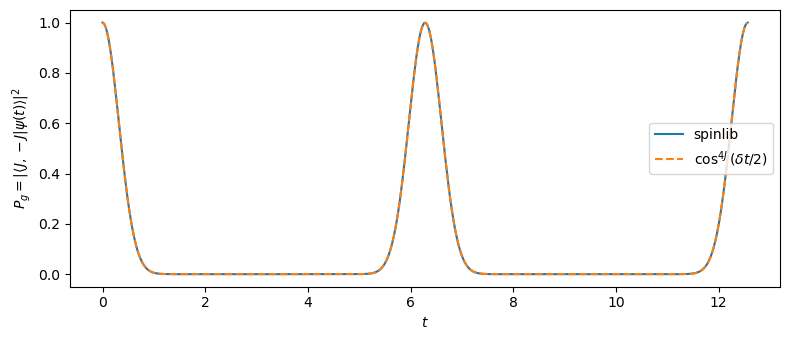

max |difference| = 2.9976021664879227e-15


In [3]:
N, delta = 21, 1.0                                       # parameters: dimension and detuning
J = (N - 1) / 2
Sx, Sy, Sz = spin_matrices(N)

times = np.linspace(0, 4*np.pi / delta, 400)
pops = scan(N, delta * Sz, times)

plt.figure(figsize=(8, 3.5))
plt.plot(times, pops[:, -1], label="spinlib")
plt.plot(times, np.cos(delta * times / 2)**(4*J), "--", label=r"$\cos^{4J}(\delta t/2)$")
plt.xlabel(r"$t$"); plt.ylabel(r"$P_g = |\langle J,-J|\psi(t)\rangle|^2$"); plt.legend(); plt.tight_layout(); plt.show()
print("max |difference| =", np.max(np.abs(pops[:, -1] - np.cos(delta * times / 2)**(4*J))))

### 3.2 Your Hamiltonian
Write $H$ in the first lines of the cell, as any Hermitian combination of `Sx`, `Sy`, `Sz` (and their products
with `@`), then rerun. The example is detuning plus one-axis twisting plus a transverse field,
$H = \delta S_z + \chi S_z^2 + \Omega S_x$.

* **Left:** $P_g(t)$.
* **Right:** the populations of all the levels $m$ against $t$ (colour scale), showing where the population goes
  when it leaves the ground state.

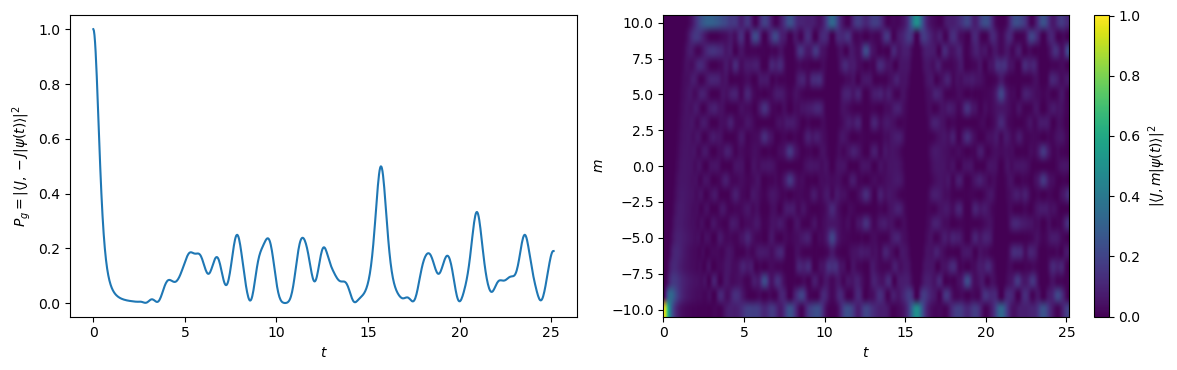

In [4]:
N = 21
J = (N - 1) / 2
Sx, Sy, Sz = spin_matrices(N)

delta, chi, Omega = 1.0, 0.1, 0.0                        # parameters
H = delta * Sz + chi * Sz @ Sz + Omega * Sx              # <-- write your Hamiltonian here

times = np.linspace(0, 8*np.pi, 800)
pops = scan(N, H, times)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
ax1.plot(times, pops[:, -1])
ax1.set_xlabel(r"$t$"); ax1.set_ylabel(r"$P_g = |\langle J,-J|\psi(t)\rangle|^2$")
im = ax2.imshow(pops.T, aspect="auto", origin="upper", cmap="viridis",
                extent=[times[0], times[-1], -J - 0.5, J + 0.5])         # row k = m from +J (top) to -J (bottom)
ax2.set_xlabel(r"$t$"); ax2.set_ylabel(r"$m$")
fig.colorbar(im, ax=ax2, label=r"$|\langle J,m|\psi(t)\rangle|^2$")
plt.tight_layout(); plt.show()

## 4. On the Bloch sphere

The state after each step of the sequence, for one time `t`, with the Hamiltonian `H` of 3.2.
The sphere is coloured with the Husimi function $Q(\theta,\varphi) = |\langle\theta,\varphi|\psi\rangle|^2$
(the overlap with the coherent state pointing at $(\theta,\varphi)$), and the red arrow is along $\langle\vec S\rangle$.
Drag to rotate, hover to read $Q$.

In [5]:
def bloch_traces(q, n_theta=61, n_phi=121, cmax=None):
    # Sphere coloured with the Husimi function Q (computed in C++), and a red arrow along <S>.
    TH, PH = np.meshgrid(np.linspace(0, np.pi, n_theta), np.linspace(0, 2*np.pi, n_phi), indexing="ij")
    x, y, z = np.sin(TH)*np.cos(PH), np.sin(TH)*np.sin(PH), np.cos(TH)
    Q = np.asarray(q.husimiQ(n_theta, n_phi), dtype=float)
    sphere = go.Surface(x=x, y=y, z=z, surfacecolor=Q, cmin=0, cmax=Q.max() if cmax is None else cmax,
                        colorscale="Viridis", colorbar=dict(title="Q", len=0.6))
    s = np.asarray(q.avgSpin(), dtype=float)                                   # mean spin <S>
    u = s / np.linalg.norm(s) if np.linalg.norm(s) > 1e-9 else np.zeros(3)     # unit vector (0 if <S> = 0)
    arrow = go.Scatter3d(x=[u[0], 1.3*u[0]], y=[u[1], 1.3*u[1]], z=[u[2], 1.3*u[2]],
                         mode="lines", line=dict(color="red", width=8), hoverinfo="skip")
    return [sphere, arrow]


def bloch_figure(q, title="", **grid):
    # The traces above plus the x, y, z axes, in a cube with hidden coordinate planes.
    axes = [go.Scatter3d(x=[-1.35*a[0], 1.35*a[0]], y=[-1.35*a[1], 1.35*a[1]], z=[-1.35*a[2], 1.35*a[2]],
                         mode="lines+text", text=["", name], line=dict(color="gray", width=2), hoverinfo="skip")
            for a, name in [((1, 0, 0), "x"), ((0, 1, 0), "y"), ((0, 0, 1), "z")]]
    fig = go.Figure(bloch_traces(q, **grid) + axes)
    hidden = dict(visible=False)
    fig.update_layout(title=title, showlegend=False, height=450, margin=dict(l=0, r=0, t=40, b=0),
                      scene=dict(xaxis=hidden, yaxis=hidden, zaxis=hidden, aspectmode="cube",
                                 camera=dict(eye=dict(x=1.15, y=0.85, z=0.65))))
    return fig

In [6]:
t = 3.0                                                  # the time of the free evolution
E, P = np.linalg.eigh(H)
q = spinlib.Qudit(N, "CSS+Z")

bloch_figure(q, "0. initial state |J, J⟩").show()
q.applyPulseXPiHalf();  bloch_figure(q, "1. after the first π/2 pulse about x").show()
q.evolve(E, P, t);      bloch_figure(q, f"2. after the evolution for t = {t:g}").show()
q.applyPulseXPiHalf();  bloch_figure(q, f"3. after the second π/2 pulse:  P_g = {ground_population(q):.3f}").show()